PANDAS

In [5]:
import pandas as pd
import os 
import numpy as np 
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

def count_df (data_path, embedding_path, NAME,slide_col='image_id', printing=False):
    features_list = []
    labels_list = []
    patient_list = []
    gleason_score = []
    gleason_primary_list = []
    gleason_secondary_list = []
    df = pd.read_excel(data_path)
    embeddings = [f for f in os.listdir(embedding_path) if f.endswith('.h5')]

    existing_h5 = 0
    # Agrega tqdm aquí
    for f in tqdm(embeddings, desc="Procesando embeddings"):
        slide_id = f.split('.h5')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]
        row = df[df[slide_col] == slide_id]

        if not row.empty:
            ruta_npy = os.path.join(embedding_path, f)
            if  os.path.exists(ruta_npy):
                existing_h5+=1

            gleason = row[['gleason_score']].values
            patient_select = row['image_id'].values
            labels_selected = row[['gleason_primary', 'gleason_secondary']].values
            labels_selected = np.array(labels_selected, dtype=int)[0]

            gleason_score.append(gleason.item())
            features_list.append(ruta_npy)
            labels_list.append(labels_selected)
            patient_list.append(patient_select)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])
    print(existing_h5)
   
    
    # Crear DataFrame con los valores
    df_gleason = pd.DataFrame({
        'Gleason_primary': gleason_primary_list,
        'Gleason_secondary': gleason_secondary_list
    })

    # Crear la tabla cruzada (conteo de combinaciones)
    tabla = pd.crosstab(df_gleason['Gleason_primary'], df_gleason['Gleason_secondary'])
  
    if printing == True:
        print(f"Nº imagenes en Base de datos {NAME} : {len(features_list)}")
        print(f"Nº de pacientes en {NAME}: {len(patient_list)}")

        plt.figure(figsize=(6,5))
        sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Gleason secundario')
        plt.ylabel('Gleason primario')
        plt.title('Distribución Gleason Primario vs Secundario')
        plt.show()

    df_train = pd.DataFrame({
        'features': features_list,
        'labels': labels_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train



Procesando embeddings: 100%|██████████| 10569/10569 [00:14<00:00, 719.70it/s]


Nº imagenes en Base de datos PANDA : 9614
Nº de pacientes en PANDA: 9614


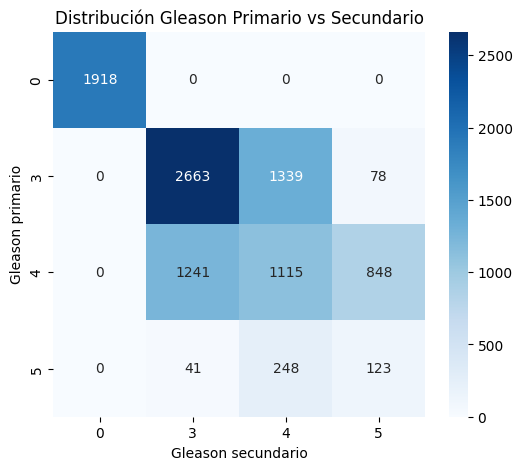

In [18]:
data_path_panda = '/workspace/data/datos_PANDAS.xlsx'
embedding_path_panda = '/workspace/data/pandas/embeddings/KEEP'
df_pandas = count_df (data_path_panda, embedding_path_panda, 'PANDA',slide_col='image_id', printing=True)

Procesando embeddings: 100%|██████████| 230/230 [00:00<00:00, 915.46it/s]


228
Nº imagenes en Base de datos SICAP : 228
Nº de pacientes en SICAP: 228


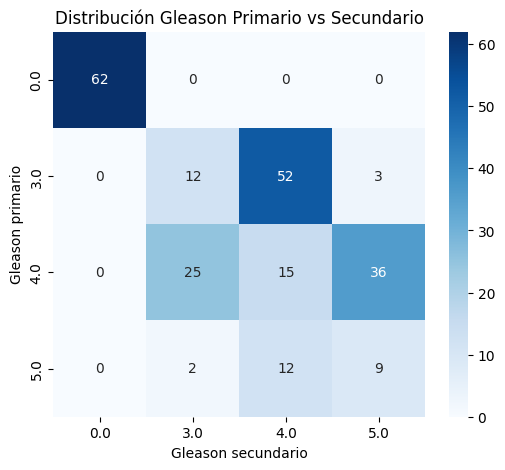

In [6]:
data_path = '/workspace/data/wsi_labels_changed_SICAP.xlsx'
embedding_path = '/workspace/data/features_SICAP/patches'
df_sicap = count_df (data_path, embedding_path, 'SICAP',slide_col='image_id', printing=True)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
import pandas as pd

def generar_tabla_resumen(df_pandas):
    # --- 1️⃣ Dividir en train, val y test ---
    train_val_idx, test_idx = train_test_split(
        df_pandas.index, test_size=0.15, stratify=df_pandas["gleason_score"]
    )

    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.10, stratify=df_pandas.loc[train_val_idx]["gleason_score"]
    )

    # Crear subconjuntos
    df_train = df_pandas.loc[train_idx]
    df_val = df_pandas.loc[val_idx]
    df_test = df_pandas.loc[test_idx]

    # --- 2️⃣ Función auxiliar para contar clases ---
    def contar_por_columna(df, columna):
        return df[columna].value_counts().sort_index()

    # --- 3️⃣ Construir tablas ---
    tipos = ['gleason_primary', 'gleason_secondary', 'gleason_score']
    tablas = {}

    for tipo in tipos:
        # Combinar en un solo DataFrame
        tabla = pd.concat([
            contar_por_columna(df_train, tipo).rename('Train'),
            contar_por_columna(df_val, tipo).rename('Validation'),
            contar_por_columna(df_test, tipo).rename('Test')
        ], axis=1).fillna(0).astype(int)

        tablas[tipo] = tabla

    # --- 4️⃣ Mostrar resultados ---
    for nombre, tabla in tablas.items():
        print(f"\n📊 Tabla resumen por {nombre.replace('_', ' ').title()}")
        print(tabla)
    
    return tablas  # Devuelve un diccionario con las 3 tablas


In [ ]:
tabla = generar_tabla_resumen(df_pandas)


📊 Tabla resumen por Gleason Primary
   Train  Validation  Test
0   1467         163   288
3   3129         348   603
4   2446         275   483
5    311          32    69

📊 Tabla resumen por Gleason Secondary
   Train  Validation  Test
0   1467         163   288
3   3010         335   600
4   2065         230   407
5    811          90   148

📊 Tabla resumen por Gleason Score
    Train  Validation  Test
0    1467         163   288
6    2036         227   400
7    1973         220   387
8     944         105   185
9     838          93   165
10     95          10    18


In [1]:
import os
import pandas as pd

# -------- CONFIGURACIÓN --------
carpeta = "/workspace/data/features_SICAP/patches_png"
excel_path = "/workspace/data/patch_coord_2.xlsx"

col_slide = "Slide_ID"
col_x = "X"
col_y = "Y"
# --------------------------------


# --- 1. Cargar Excel ---
df_excel = pd.read_excel(excel_path)

# Validación
for col in [col_slide, col_x, col_y]:
    if col not in df_excel.columns:
        raise ValueError(f"❌ La columna '{col}' no existe en el Excel.")


# --- 2. Extraer información de archivos ---
patchid_list = []
coord_x_list = []
coord_y_list = []
file_list = []

for archivo in os.listdir(carpeta):
    if not archivo.lower().endswith((".png", ".jpg", ".jpeg", ".h5")):
        continue  # ignora otros tipos de archivo

    nombre = os.path.splitext(archivo)[0]  # quitar extensión
    
    # Ejemplo:   19B008091A_4x3200_y4560
    try:
        patch_id = nombre.split("x")[0][:-1]      # "19B008091A_4"
        coords = nombre.split("x")[1]             # "3200_y4560"

        coord_x = coords.split("_")[0]            # "3200"
        coord_y = coords.split("y")[1]            # "4560"
    except Exception as e:
        print(f"⚠️ No se pudo parsear el nombre: {archivo}")
        continue

    patchid_list.append(patch_id)
    coord_x_list.append(int(coord_x))
    coord_y_list.append(int(coord_y))
    file_list.append(archivo)


# --- 3. Crear dataframe nuevo con los datos extraídos ---
df_files = pd.DataFrame({
    "archivo": file_list,
    "Slide_ID": patchid_list,
    "X": coord_x_list,
    "Y": coord_y_list
})

print("\n📘 DataFrame generado desde los archivos:")
print(df_files.head())


# --- 4. Comparación con el Excel ---
df_merged = df_files.merge(
    df_excel[[col_slide, col_x, col_y]],
    on=["Slide_ID", "X", "Y"],
    how="left",
    indicator=True
)

# Archivos encontrados en Excel
df_existen = df_merged[df_merged["_merge"] == "both"]

# Archivos NO encontrados en Excel
df_no_existen = df_merged[df_merged["_merge"] == "left_only"]


print("\n✅ Coincidencias encontradas:", len(df_existen))
print("❌ No encontradas:", len(df_no_existen))



📘 DataFrame generado desde los archivos:
                         archivo       Slide_ID     X     Y
0  16B0003388_13_x1105_y3113.png  16B0003388_13  1105  3113
1  16B0003388_13_x1105_y3625.png  16B0003388_13  1105  3625
2  16B0003388_13_x1105_y4137.png  16B0003388_13  1105  4137
3  16B0003388_13_x1617_y3625.png  16B0003388_13  1617  3625
4  16B0003388_13_x1617_y4137.png  16B0003388_13  1617  4137

✅ Coincidencias encontradas: 2847
❌ No encontradas: 4859


In [ ]:
import torch
import numpy as np

def analyze_gradients(model):
    grad_stats = {}
    all_grads = []

    # Recorremos todos los parámetros del modelo
    for name, param in model.named_parameters():
        if param.grad is None:
            continue

        g = param.grad.detach().abs().cpu().numpy()

        grad_stats[name] = {
            "mean": float(g.mean()),
            "std": float(g.std()),
            "min": float(g.min()),
            "max": float(g.max()),
            "p25": float(np.percentile(g, 25)),
            "p50": float(np.percentile(g, 50)),
            "p75": float(np.percentile(g, 75)),
            "p90": float(np.percentile(g, 90)),
            "p95": float(np.percentile(g, 95)),
            "p99": float(np.percentile(g, 99)),
        }

        all_grads.append(g.reshape(-1))

    # Concatenamos todos los gradientes del modelo
    all_grads = np.concatenate(all_grads)

    global_stats = {
        "GLOBAL_mean": float(all_grads.mean()),
        "GLOBAL_std": float(all_grads.std()),
        "GLOBAL_min": float(all_grads.min()),
        "GLOBAL_max": float(all_grads.max()),
        "GLOBAL_p50": float(np.percentile(all_grads, 50)),
        "GLOBAL_p90": float(np.percentile(all_grads, 90)),
        "GLOBAL_p99": float(np.percentile(all_grads, 99)),
    }

    # Detección automática de problemas
    issues = []
    if global_stats["GLOBAL_mean"] < 1e-4:
        issues.append("⚠️ Posible vanishing gradients (<1e-4 global mean).")
    if global_stats["GLOBAL_max"] > 1:
        issues.append("⚠️ Posible exploding gradients (>1 global max).")

    return grad_stats, global_stats, issues


# --------------------
# USO:
# --------------------
# forward
# loss = criterion(outputs, targets)
# loss.backward()

# analyze
grad_details, global_summary, alerts = analyze_gradients(model)

# imprimir resultados
print(global_summary)
print(alerts)
